In [25]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

In [21]:
df_train1= pd.read_csv("../data/case1/train1.csv")
df_test1 = pd.read_csv("../data/case1/test1.csv")

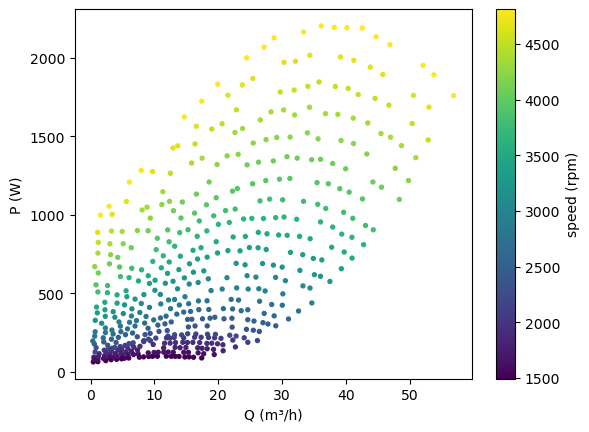

In [12]:
plt.scatter(df_train1["flow_m3_h"], df_train1["power_w"], c=df_train1["speed_rpm"], s=8)
plt.colorbar(label="speed (rpm)")
plt.xlabel("Q (m³/h)"); plt.ylabel("P (W)")
plt.show()

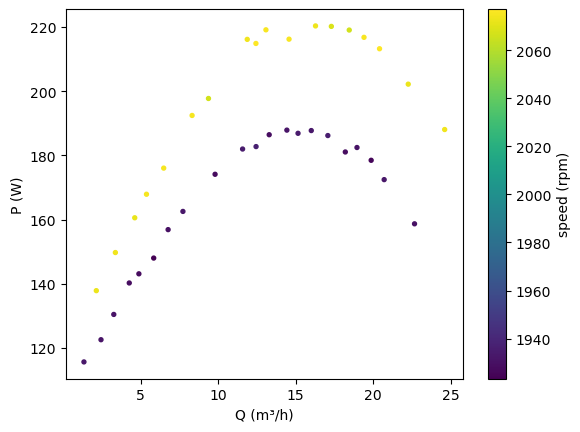

In [20]:
df_filter = df_train1[(df_train1["speed_rpm"] > 1900) & (df_train1["speed_rpm"] < 2100)]
plt.scatter(df_filter["flow_m3_h"], df_filter["power_w"], c=df_filter["speed_rpm"], s=8)
plt.colorbar(label="speed (rpm)")
plt.xlabel("Q (m³/h)"); plt.ylabel("P (W)")
plt.show()

In [22]:
#subtask 1
def make_features(df):
    #We convert rpm to krpm dividing by 1000
    n = df["speed_rpm"] / 1000 
    Q = df["flow_m3_h"]

    return pd.DataFrame({f"n{i}_Q{j}": n**i * Q**j
                        for i in range(4) for j in range(4)
                        if (i, j) != (0, 0)})

x_train, y_train = make_features(df_train1), df_train1["power_w"]
x_test, y_test = make_features(df_test1), df_test1["power_w"]
x_train.shape

(480, 15)

In [26]:
#Subtask 2 - using root mean square error (rmse)
model_all = LinearRegression().fit(x_train, y_train)

rmse_train_all = np.sqrt(np.mean((model_all.predict(x_train) - y_train) ** 2))
print(rmse_train_all)

10.212696850805779


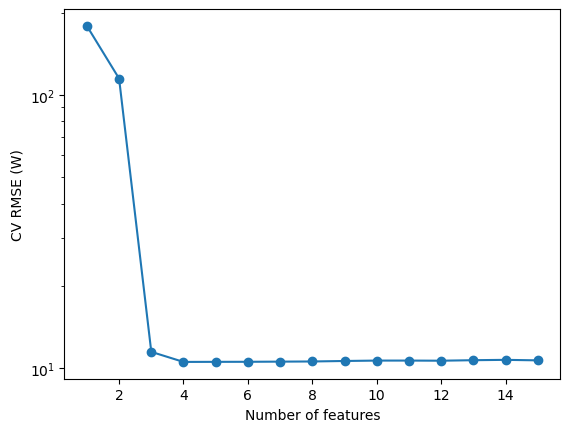

[(1, 'n3_Q0', np.float64(178.74)), (2, 'n2_Q1', np.float64(114.75)), (3, 'n0_Q3', np.float64(11.47)), (4, 'n1_Q2', np.float64(10.54)), (5, 'n0_Q1', np.float64(10.55)), (6, 'n0_Q2', np.float64(10.55)), (7, 'n1_Q0', np.float64(10.57)), (8, 'n2_Q0', np.float64(10.58)), (9, 'n1_Q1', np.float64(10.62)), (10, 'n2_Q2', np.float64(10.66)), (11, 'n3_Q2', np.float64(10.66)), (12, 'n3_Q1', np.float64(10.65)), (13, 'n1_Q3', np.float64(10.69)), (14, 'n2_Q3', np.float64(10.73)), (15, 'n3_Q3', np.float64(10.68))]


In [29]:
#Subtask 3 - select features with forward stepwise selection. CV = Coefficient of variation
kf= KFold(n_splits=5, shuffle=True, random_state=0)

def cv_rmse(cols):
    scores = cross_val_score(LinearRegression(), x_train[cols], y_train, cv=kf, scoring="neg_root_mean_squared_error")
    return -scores.mean()

selected, remaining, cv_curve = [], list(x_train.columns), []
while remaining:
    best_col = min(remaining, key=lambda c: cv_rmse(selected + [c]))
    selected.append(best_col)
    remaining.remove(best_col)
    cv_curve.append(cv_rmse(selected))

plt.plot(range(1, len(cv_curve) + 1), cv_curve, marker="o")
plt.yscale("log")
plt.xlabel("Number of features"); plt.ylabel("CV RMSE (W)")
plt.show()
print(list(zip(range(1, len(selected) + 1), selected, np.round(cv_curve,2))))



RMSE:  10.358675167960909
MAE:  8.063035282239413
MAPE(%):  2.0300347024216148
P = 40.9+7.66 * n3_Q0+2.41 * n2_Q1-0.00838 * n0_Q3-0.0496 * n1_Q2


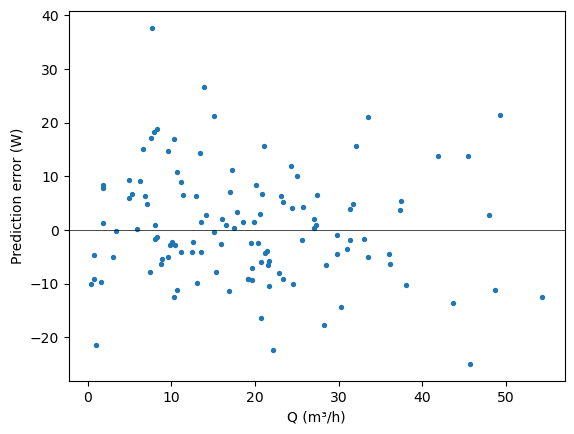

In [32]:
# Subtask 4 - Final result with K = 4. MAE= Mean absolute error. MAPE = Mean absolute percentage error
K = 4
chosen = selected[:K]

final= LinearRegression().fit(x_train[chosen], y_train)

pred = final.predict(x_test[chosen])
err = pred - y_test

print("RMSE: ", np.sqrt(np.mean(err ** 2)))
print("MAE: ", np.mean(np.abs(err)))
print("MAPE(%): ", np.mean(np.abs(err) / y_test) * 100)

expr = f"P = {final.intercept_:.3g}" + "".join(
    f"{coef:+.3g} * {name}" for name, coef in zip(chosen, final.coef_))
print(expr)

plt.scatter(df_test1["flow_m3_h"], err, s=8)
plt.axhline(0, color="k", lw= 0.5)
plt.xlabel("Q (m³/h)"); plt.ylabel("Prediction error (W)")
plt.show()